In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import csv
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)
import sys
np.set_printoptions(threshold=sys.maxsize)
from IPython.display import display

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

df = pd.read_csv(
    "covid_cleaned.csv",
    sep=",",
    engine="python",
    quoting=csv.QUOTE_MINIMAL
)

In [3]:
df.head()

,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,DATE_DIED,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,COPD,ASTHMA,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU,INTUBED_original,ICU_original,PREGNANT_original,PNEUMONIA_original,DIABETES_original,COPD_original,ASTHMA_original,INMSUPR_original,HIPERTENSION_original,OTHER_DISEASE_original,CARDIOVASCULAR_original,OBESITY_original,RENAL_CHRONIC_original,TOBACCO_original,INTUBED_NOT_APPLICABLE,ICU_NOT_APPLICABLE,PREGNANT_NOT_APPLICABLE,INTUBED_UNKNOWN,ICU_UNKNOWN,PREGNANT_UNKNOWN,PNEUMONIA_NOT_APPLICABLE,PNEUMONIA_UNKNOWN,DIABETES_NOT_APPLICABLE,DIABETES_UNKNOWN,COPD_NOT_APPLICABLE,COPD_UNKNOWN,ASTHMA_NOT_APPLICABLE,ASTHMA_UNKNOWN,INMSUPR_NOT_APPLICABLE,INMSUPR_UNKNOWN,HIPERTENSION_NOT_APPLICABLE,HIPERTENSION_UNKNOWN,OTHER_DISEASE_NOT_APPLICABLE,OTHER_DISEASE_UNKNOWN,CARDIOVASCULAR_NOT_APPLICABLE,CARDIOVASCULAR_UNKNOWN,OBESITY_NOT_APPLICABLE,OBESITY_UNKNOWN,RENAL_CHRONIC_NOT_APPLICABLE,RENAL_CHRONIC_UNKNOWN,TOBACCO_NOT_APPLICABLE,TOBACCO_UNKNOWN,DATE_DIED_original,NO_DEATH_DATE,HAS_DEATH_DATE
0,2,1,1,1,2020-05-03,NaN,1.00,65,2.00,2.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,3,NaN,97,97,2,1,2,2,2,2,1,2,2,2,2,2,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,03/05/2020,False,True
1,2,1,2,1,2020-06-03,NaN,1.00,72,NaN,2.00,2.00,2.00,2.00,1.00,2.00,2.00,1.00,1.00,2.00,5,NaN,97,97,97,1,2,2,2,2,1,2,2,1,1,2,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,03/06/2020,False,True
2,2,1,2,2,2020-06-09,1.00,2.00,55,NaN,1.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,3,2.00,1,2,97,2,1,2,2,2,2,2,2,2,2,2,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,09/06/2020,False,True
3,2,1,1,1,2020-06-12,NaN,2.00,53,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,7,NaN,97,97,2,2,2,2,2,2,2,2,2,2,2,2,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,12/06/2020,False,True
4,2,1,2,1,2020-06-21,NaN,2.00,68,NaN,1.00,2.00,2.00,2.00,1.00,2.00,2.00,2.00,2.00,2.00,3,NaN,97,97,97,2,1,2,2,2,1,2,2,2,2,2,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,21/06/2020,False,True


The age distribution shows that patient records are concentrated among adults aged approximately 25 to 50 years, indicating that this age group represents a large proportion of the dataset.

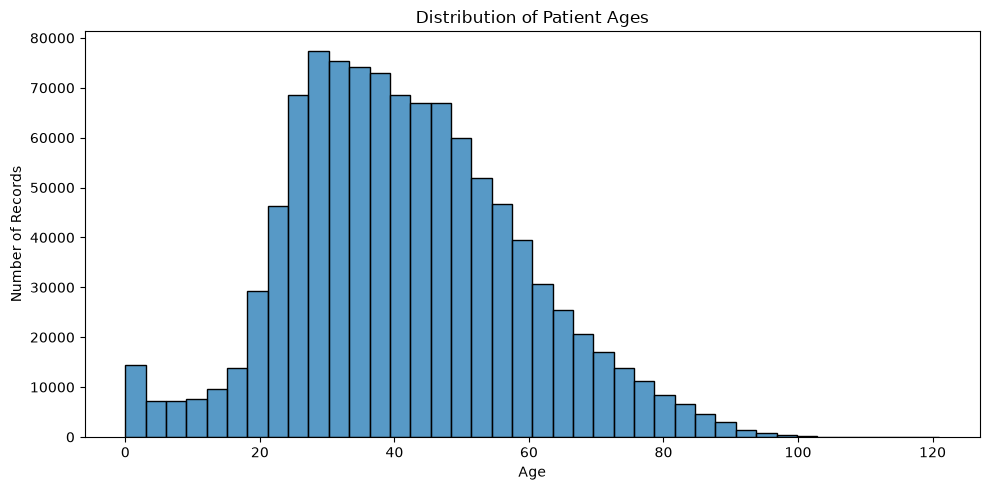

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="AGE",
    bins=40
)

plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


The distribution of COVID-19 classifications shows that codes 3 and 7 account for the largest numbers of records. Code 3 represents laboratory-confirmed COVID-19 cases, while code 7 represents negative SARS-CoV-2 test results.

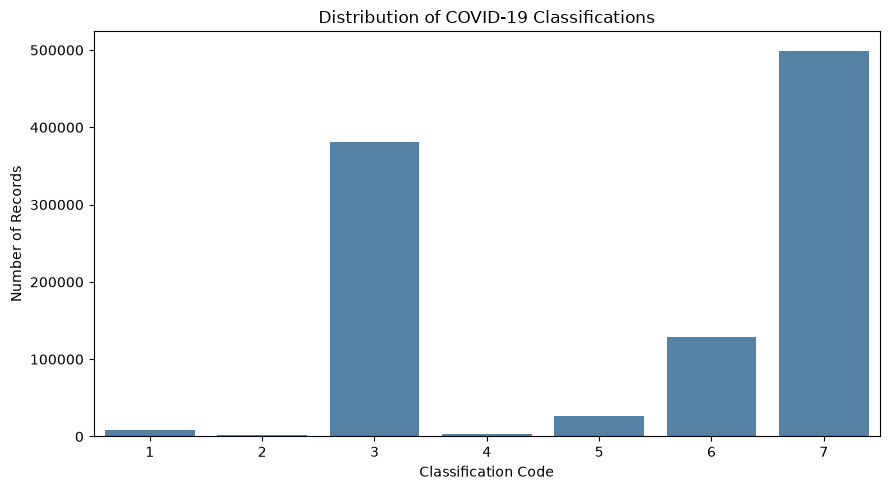

In [6]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="CLASIFFICATION_FINAL",
    color="steelblue"
)

plt.title("Distribution of COVID-19 Classifications")
plt.xlabel("Classification Code")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

The distribution shows that most patient records belong to code 1 (outpatients), while a smaller proportion belong to code 2 (hospitalized inpatients).

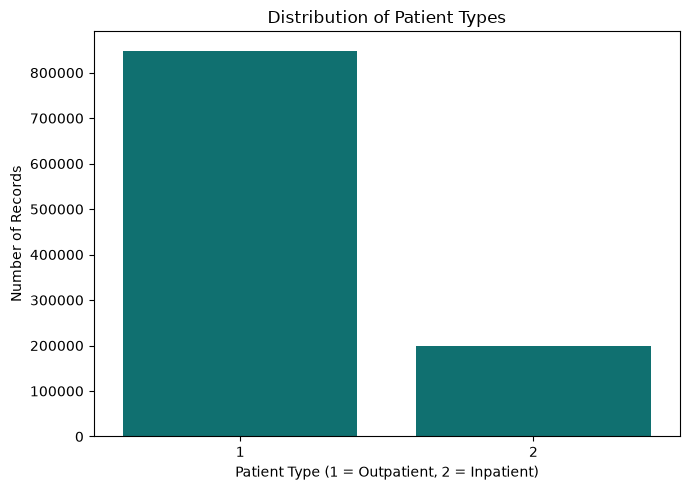

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="PATIENT_TYPE",
    color="teal"
)

plt.title("Distribution of Patient Types")
plt.xlabel("Patient Type (1 = Outpatient, 2 = Inpatient)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

Most records do not contain a recorded death date, while a smaller proportion contain one. This comparison describes the availability of recorded death dates in the dataset.

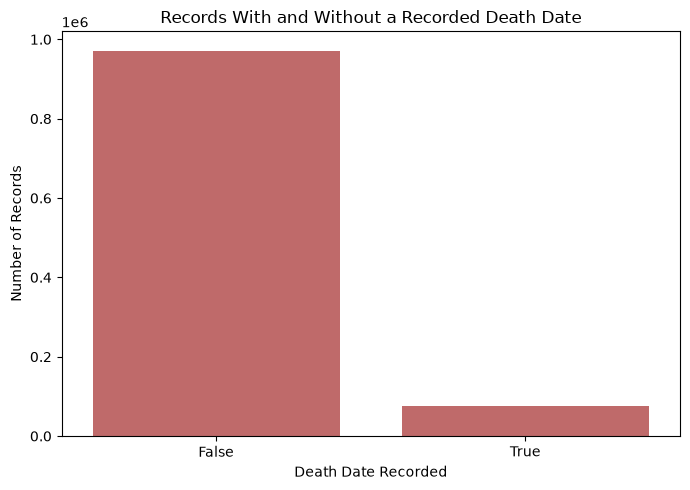

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="HAS_DEATH_DATE",
    color="indianred"
)

plt.title("Records With and Without a Recorded Death Date")
plt.xlabel("Death Date Recorded")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

The box plot compares patient age distributions across COVID-19 classification codes. If confirmed by the plot, code 2 has a higher median patient age than the other classification groups.

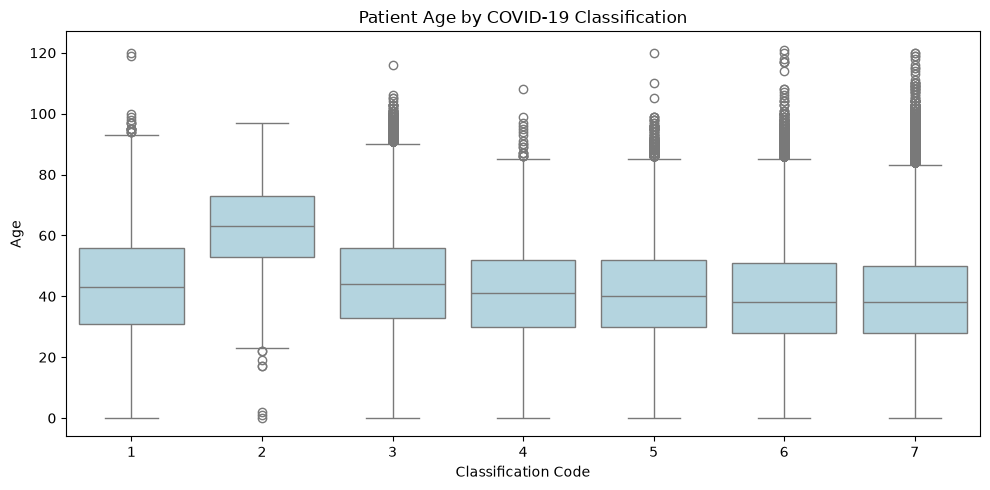

In [9]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="CLASIFFICATION_FINAL",
    y="AGE",
    color="lightblue"
)

plt.title("Patient Age by COVID-19 Classification")
plt.xlabel("Classification Code")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

The box plot compares patient ages between records with and without a recorded death date. If confirmed by the plot, records with a recorded death date have a higher median age. This indicates an association, not a causal relationship.

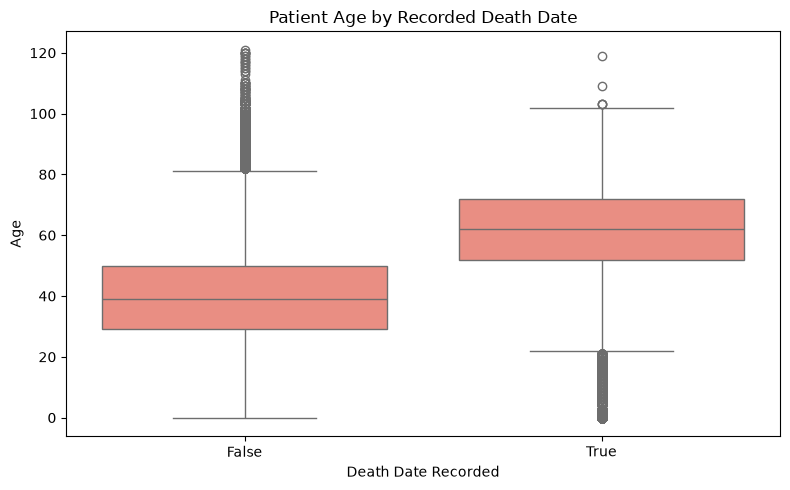

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="HAS_DEATH_DATE",
    y="AGE",
    color="salmon"
)

plt.title("Patient Age by Recorded Death Date")
plt.xlabel("Death Date Recorded")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

The stacked bar chart compares the percentage distribution of COVID-19 classification codes between outpatients and hospitalized inpatients, highlighting differences in classification patterns between the two groups.

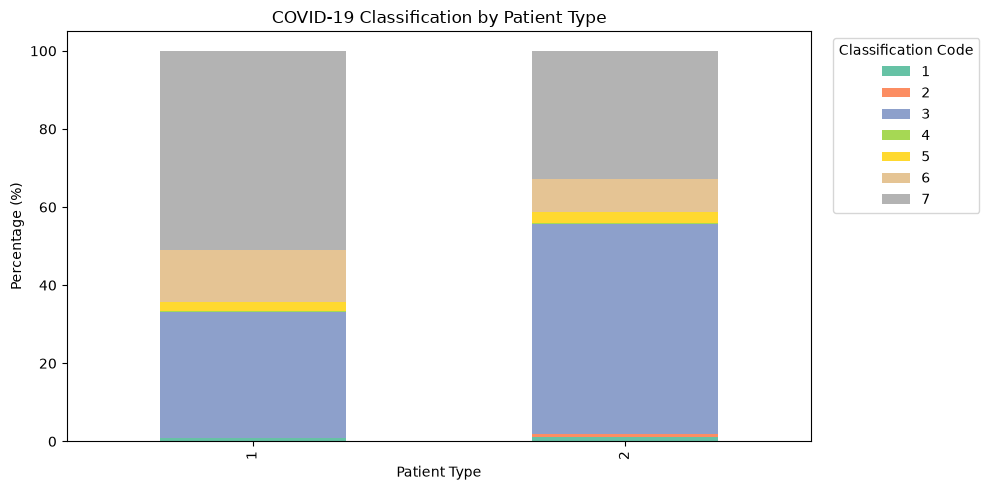

In [11]:
patient_class = pd.crosstab(
    df["PATIENT_TYPE"],
    df["CLASIFFICATION_FINAL"],
    normalize="index"
) * 100

patient_class.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    colormap="Set2"
)

plt.title("COVID-19 Classification by Patient Type")
plt.xlabel("Patient Type")
plt.ylabel("Percentage (%)")
plt.legend(title="Classification Code", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

The chart compares the percentage of records with a recorded death date among patients with and without selected chronic conditions. Any observed differences indicate associations and should not be interpreted as evidence that these conditions caused the recorded deaths.

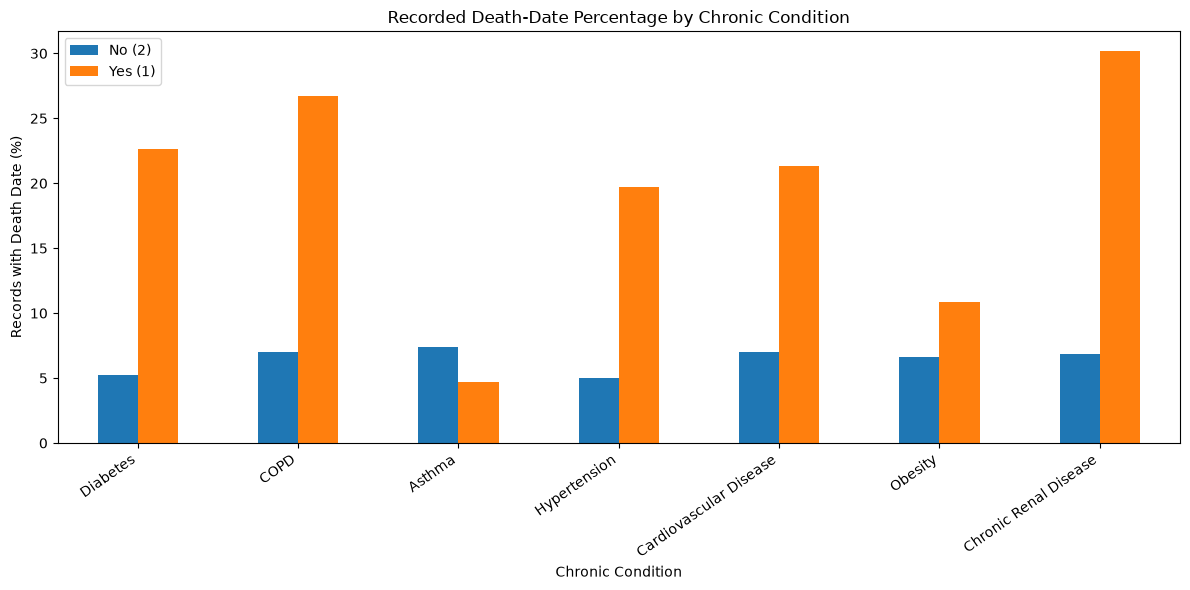

In [12]:
chronic_cols = [
    "DIABETES",
    "COPD",
    "ASTHMA",
    "HIPERTENSION",
    "CARDIOVASCULAR",
    "OBESITY",
    "RENAL_CHRONIC"
]

death_rates = {}

for col in chronic_cols:
    temp = df[[col, "HAS_DEATH_DATE"]].dropna(subset=[col])

    rates = (
        temp.groupby(col, observed=True)["HAS_DEATH_DATE"]
        .mean() * 100
    )

    death_rates[col] = rates.reindex([2, 1])

death_rates_df = pd.DataFrame(death_rates, index=[2, 1]).T
death_rates_df.index = [
    "Diabetes",
    "COPD",
    "Asthma",
    "Hypertension",
    "Cardiovascular Disease",
    "Obesity",
    "Chronic Renal Disease"
]
death_rates_df.columns = ["No (2)", "Yes (1)"]

death_rates_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Recorded Death-Date Percentage by Chronic Condition")
plt.xlabel("Chronic Condition")
plt.ylabel("Records with Death Date (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

The prevalence chart compares the percentages of patients with selected chronic conditions among records with known values. The most frequently recorded conditions can be identified by comparing the bar lengths.

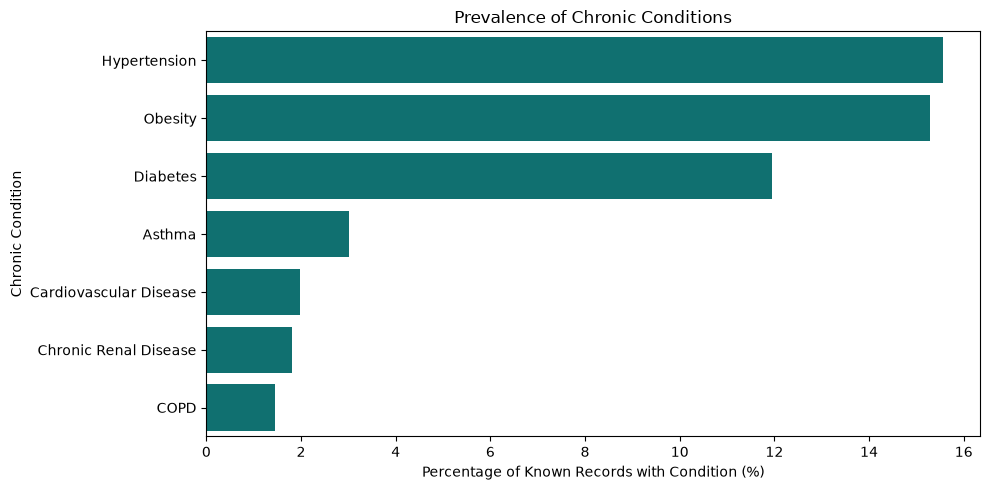

In [13]:
prevalence = {}

for col in chronic_cols:
    known = df[col].dropna()
    prevalence[col] = (known.eq(1).mean() * 100)

prevalence_df = (
    pd.Series(prevalence)
    .sort_values(ascending=False)
    .rename(index={
        "DIABETES": "Diabetes",
        "COPD": "COPD",
        "ASTHMA": "Asthma",
        "HIPERTENSION": "Hypertension",
        "CARDIOVASCULAR": "Cardiovascular Disease",
        "OBESITY": "Obesity",
        "RENAL_CHRONIC": "Chronic Renal Disease"
    })
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=prevalence_df.values,
    y=prevalence_df.index,
    color="teal"
)

plt.title("Prevalence of Chronic Conditions")
plt.xlabel("Percentage of Known Records with Condition (%)")
plt.ylabel("Chronic Condition")
plt.tight_layout()
plt.show()